In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [3]:
df = pd.read_csv("uber.csv")

In [4]:
print("First 5 Rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

# 2. Data Preprocessing
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
df = df.dropna()

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)
df = df.dropna(subset=["pickup_datetime"])


First 5 Rows:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                

In [5]:
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

df = df.drop(columns=["pickup_datetime"])

# Remove invalid values
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] >= 1) &
    (df["passenger_count"] <= 6) &
    df["pickup_latitude"].between(-90, 90) &
    df["dropoff_latitude"].between(-90, 90) &
    df["pickup_longitude"].between(-180, 180) &
    df["dropoff_longitude"].between(-180, 180)
].copy()

In [6]:
# Calculate distance using Haversine formula
lat1 = np.radians(df["pickup_latitude"])
lat2 = np.radians(df["dropoff_latitude"])
lon1 = np.radians(df["pickup_longitude"])
lon2 = np.radians(df["dropoff_longitude"])

a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lon2 - lon1) / 2) ** 2
)

df["distance"] = 6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


In [7]:
df = df[
    (df["distance"] > 0) &
    (df["distance"] <= 100) &
    (df["fare_amount"] <= 500)
].copy()

print("\nCleaned Dataset:")
print(df.head())
print("Number of rows after cleaning:", len(df))

# 3. Identify Outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower) |
    (df["fare_amount"] > upper)
]

print("\nNumber of Fare Outliers:", len(outliers))


Cleaned Dataset:
   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  day  month  distance  
0         40.723217                1    19    7      5  1.683323  
1         40.750325                1    20   17      7  2.457590  
2         40.772647                1    21   24      8  5.036377  
3         40.803349                3     8   26      6  1.661683  
4         40.761247                5    17   28      8  4.475450  
Number of rows after cleaning: 193191

Number of Fare Outliers: 16540


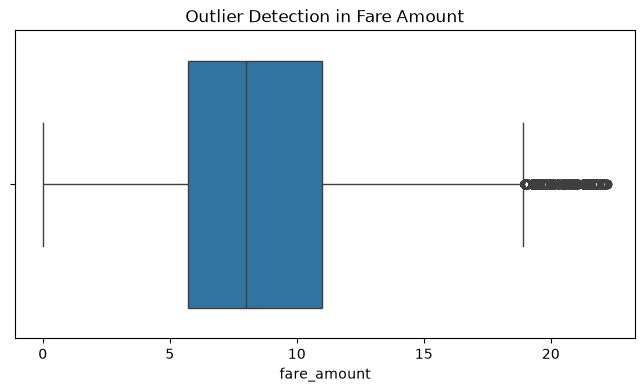

In [9]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Outlier Detection in Fare Amount")
plt.show()

# Remove fare outliers
df = df[
    df["fare_amount"].between(lower, upper)
].copy()


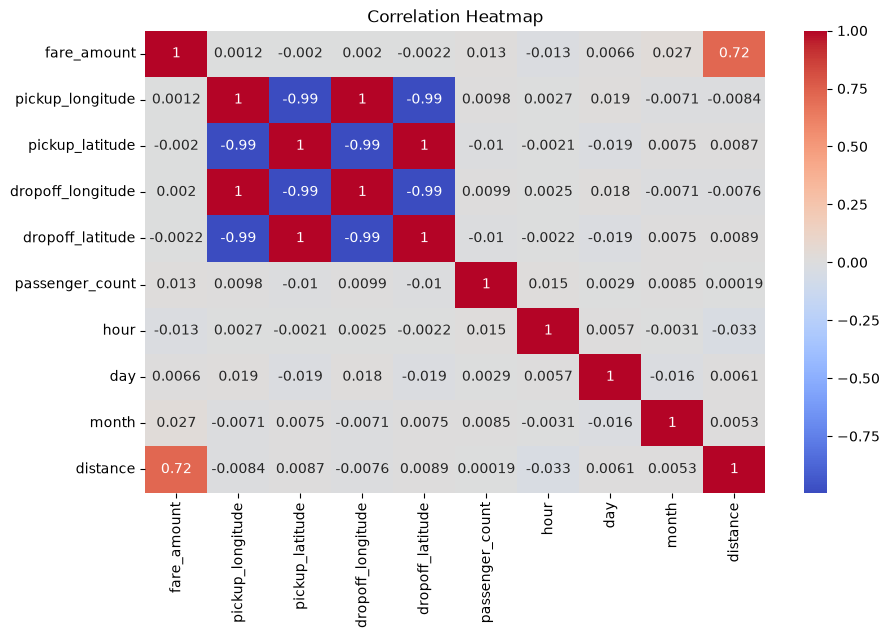


Correlation with Fare Amount:
fare_amount          1.000000
distance             0.723498
month                0.026705
passenger_count      0.013017
day                  0.006575
dropoff_longitude    0.002047
pickup_longitude     0.001204
pickup_latitude     -0.002014
dropoff_latitude    -0.002214
hour                -0.013121
Name: fare_amount, dtype: float64


In [11]:
#Correlation Analysis
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

print("\nCorrelation with Fare Amount:")
print(df.corr(numeric_only=True)["fare_amount"].sort_values(ascending=False))


In [12]:
# 5. Prepare Data
X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [13]:
# 6. Linear Regression Model
lr = LinearRegression()
lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

# 7. Random Forest Regression Model
rf = RandomForestRegressor(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)


In [14]:
# 8. Evaluate Models
def evaluate_model(name, actual, predicted):
    print("\n", name)
    print("R2 Score:", round(r2_score(actual, predicted), 4))
    print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 4))
    print("MAE:", round(mean_absolute_error(actual, predicted), 4))

evaluate_model("Linear Regression Results", y_test, pred_lr)
evaluate_model("Random Forest Results", y_test, pred_rf)


 Linear Regression Results
R2 Score: 0.5891
RMSE: 2.6465
MAE: 1.8846

 Random Forest Results
R2 Score: 0.7339
RMSE: 2.1296
MAE: 1.5052


In [15]:
# 9. Compare Models
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [
        r2_score(y_test, pred_lr),
        r2_score(y_test, pred_rf)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_lr)),
        np.sqrt(mean_squared_error(y_test, pred_rf))
    ],
    "MAE": [
        mean_absolute_error(y_test, pred_lr),
        mean_absolute_error(y_test, pred_rf)
    ]
})

print("\nModel Comparison:")
print(results.to_string(index=False))



Model Comparison:
            Model  R2 Score     RMSE      MAE
Linear Regression  0.589076 2.646454 1.884563
    Random Forest  0.733913 2.129586 1.505198


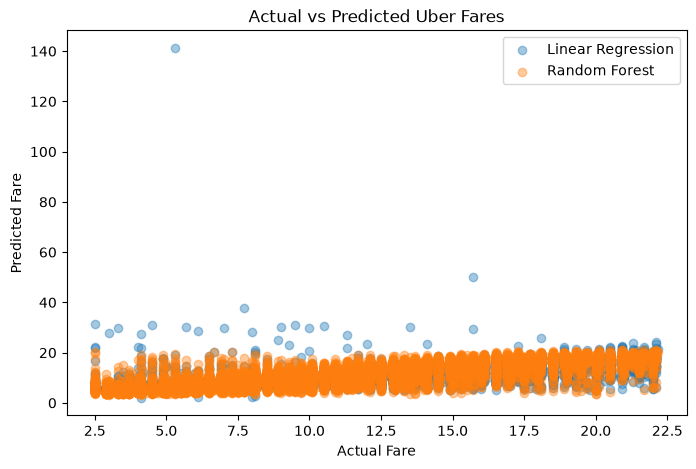

In [16]:
# 10. Actual vs Predicted Plot
plt.figure(figsize=(8, 5))
plt.scatter(y_test, pred_lr, alpha=0.4, label="Linear Regression")
plt.scatter(y_test, pred_rf, alpha=0.4, label="Random Forest")
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Uber Fares")
plt.legend()
plt.show()

In [17]:
# 11. Predict Fare for a Test Ride
sample = X_test.iloc[[0]]

print("\nSample Ride Prediction:")
print("Actual Fare:", round(y_test.iloc[0], 2))
print("Linear Regression Prediction:", round(pred_lr[0], 2))
print("Random Forest Prediction:", round(pred_rf[0], 2))

# Conclusion
if r2_score(y_test, pred_rf) > r2_score(y_test, pred_lr):
    print("\nRandom Forest performs better based on R2 Score.")
else:
    print("\nLinear Regression performs better based on R2 Score.")


Sample Ride Prediction:
Actual Fare: 5.3
Linear Regression Prediction: 7.22
Random Forest Prediction: 5.9

Random Forest performs better based on R2 Score.
